Output()

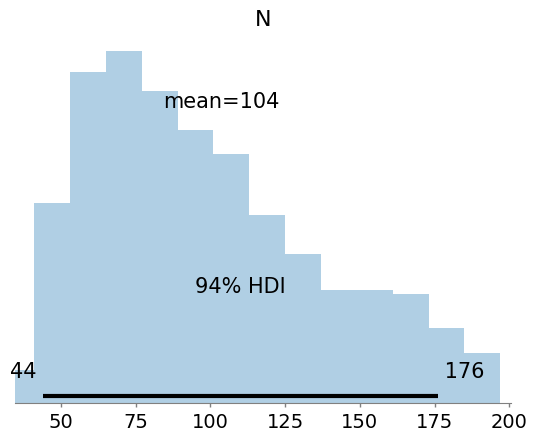

Mean: 103.73725
Median: 97.0
HDI: [ 45 181]
Estimare clasica: 75.0
P(N > 100): 0.465


Output()

Output()

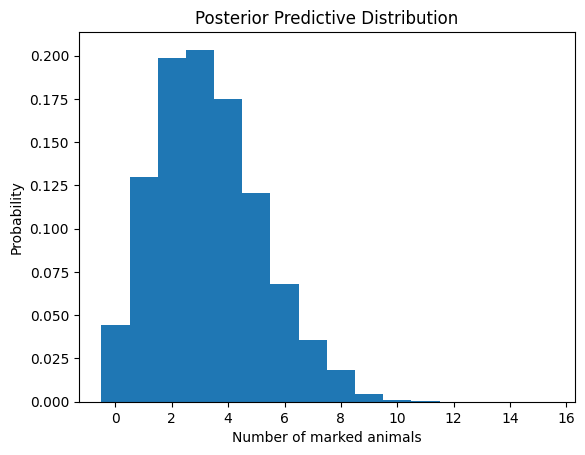

In [2]:
#Exercise 1 (Estimate the total number of animals in the population)

import pymc as pm
import arviz as az
import numpy as np
import matplotlib.pyplot as plt

M = 20
n = 15
Y = 4
#a
with pm.Model() as model:

  N = pm.DiscreteUniform("N", lower = 20, upper = 200)

  obs = pm.HyperGeometric("obs", N = N, k = M, n = n, observed = Y)

  idata = pm.sample(draws = 2000, tune = 1000, chains = 4, random_seed = 42)

  az.plot_posterior(idata, var_names=["N"])
  plt.savefig("ex1_a_posterior_N.png", dpi=300, bbox_inches="tight")

  plt.show()

#b

# Posterior mean E[N|Y=4]

posterior = idata.posterior["N"].values.flatten()
media = np.mean(posterior)
print("Mean:", media)

# Posterior median

mediana = np.median(posterior)
print("Median:",mediana)

# 95% HDI interval


hdi = az.hdi(posterior, hdi_prob=0.95)
print("HDI:", hdi)

# N^=(M*n)/Y => N^=(20*15)/4 => N^=75 => 75 animals in clasic estimation

estimare_clasica = (M * n) / Y

print("Estimare clasica:", estimare_clasica)

#c P(N>100|y=4)

probabilitate = np.mean(posterior > 100)

print("P(N > 100):", probabilitate)

#d

with pm.Model() as model:
    N = pm.DiscreteUniform("N", lower=20, upper=200)

    obs = pm.HyperGeometric("obs", N=N, k=M, n=n, observed=Y)

    y_new = pm.HyperGeometric("y_new", N=N, k=M, n=15)

    idata = pm.sample(draws=2000, tune=1000, chains=4, random_seed=42)

    predictive = pm.sample_posterior_predictive(idata, var_names=["y_new"], random_seed=42)

    y_new_samples = predictive.posterior_predictive["y_new"].values.flatten()

plt.hist(y_new_samples, bins=np.arange(-0.5, 16.5, 1), density=True)
plt.xlabel("Number of marked animals")
plt.ylabel("Probability")
plt.title("Posterior Predictive Distribution")
plt.savefig("ex1_d_predictive.png", dpi=300, bbox_inches="tight")
plt.show()

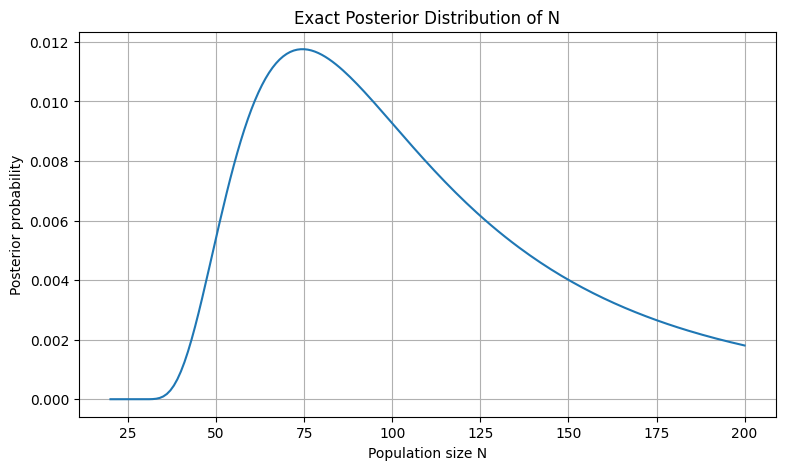

Exact posterior mean: 102.61324041811847
Exact posterior median: 95


In [4]:
from scipy.stats import hypergeom
import numpy as np
import matplotlib.pyplot as plt
#a
N_values = np.arange(20, 201)

likelihood = hypergeom.pmf(Y, N_values, M, n)

posterior_exact = likelihood / np.sum(likelihood)

plt.figure(figsize=(9, 5))
plt.plot(N_values, posterior_exact)
plt.xlabel("Population size N")
plt.ylabel("Posterior probability")
plt.title("Exact Posterior Distribution of N")
plt.grid(True)
plt.show()
#b
mean_exact = np.sum(N_values * posterior_exact)

median_exact = N_values[np.searchsorted(np.cumsum(posterior_exact), 0.5)]

print("Exact posterior mean:", mean_exact)
print("Exact posterior median:", median_exact)

Exercise 1 (d)

The posterior predictive distribution estimates the number of marked animals that could be found in a new capture of 15 animals.

This distribution considers two sources of uncertainty:
- The uncertainty about the total population size (N).
- The random variation of a new capture.
The difference is that the posterior distribution estimates the total population size (N), while the posterior predictive distribution estimates the number of marked animals in a future capture.

Output()

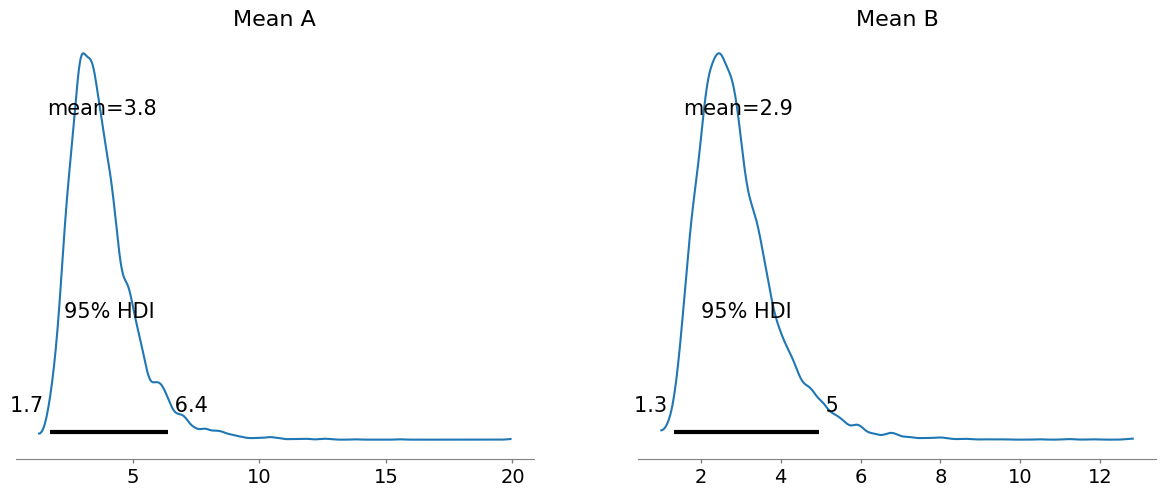

P(B is faster than A): 0.711


Output()

P(new B patient recovers faster): 0.50075


In [ ]:
#Exercise 2

import pymc as pm
import arviz as az
import numpy as np
import matplotlib.pyplot as plt

A = [3.2, 4.1, 2.8, 5.0, 3.7, 4.5, 3.0, 3.9]
B = [2.1, 2.8, 3.4, 2.5, 3.0, 2.2, 3.6, 2.7]
#a

with pm.Model() as model:

    lambda_A = pm.Gamma("lambda_A", alpha=2, beta=4)
    lambda_B = pm.Gamma("lambda_B", alpha=2, beta=4)

    obs_A = pm.Exponential("obs_A", lam=lambda_A, observed=A)

    obs_B = pm.Exponential("obs_B", lam=lambda_B, observed=B)

    idata = pm.sample(draws=2000, tune=1000, chains=4, random_seed=42)

#b

lambda_A_samples = idata.posterior["lambda_A"].values.flatten()
lambda_B_samples = idata.posterior["lambda_B"].values.flatten()

mean_A = 1 / lambda_A_samples
mean_B = 1 / lambda_B_samples

az.plot_posterior({"Mean A": mean_A, "Mean B": mean_B}, hdi_prob=0.95)
plt.savefig("ex2_b_posterior_means.png", dpi=300, bbox_inches="tight")
plt.show()

#c P(E[XB]<E[XA]|date)

prob = np.mean(mean_B < mean_A)

print("P(B is faster than A):", prob)


#d

with pm.Model() as predictive_model:

    lambda_A = pm.Gamma("lambda_A", alpha=2, beta=4)
    lambda_B = pm.Gamma("lambda_B", alpha=2, beta=4)

    x_A = pm.Exponential("x_A", lam=lambda_A)
    x_B = pm.Exponential("x_B", lam=lambda_B)

    predictive_idata = pm.sample(draws=2000, tune=1000, chains=4, random_seed=42)

x_A_samples = predictive_idata.posterior["x_A"].values.flatten()
x_B_samples = predictive_idata.posterior["x_B"].values.flatten()

prob_new = np.mean(x_B_samples < x_A_samples)

print("P(new B patient recovers faster):", prob_new)

Exercise 2 (d)

The predictive probability estimates the chance that a new patient treated with treatment B recovers faster than a new patient treated with treatment A.

This probability is different from the probability calculated in point C.

In point C, we compare the mean recovery times of the two treatments: \(1/lambda_A) and \(1/lambda_B).

In point D, we compare the individual recovery times of two new patients.

The difference is that individual recovery times are random. Even if treatment B has a lower mean recovery time, this does not guarantee that every patient treated with B will recover faster than a patient treated with A.

Output()

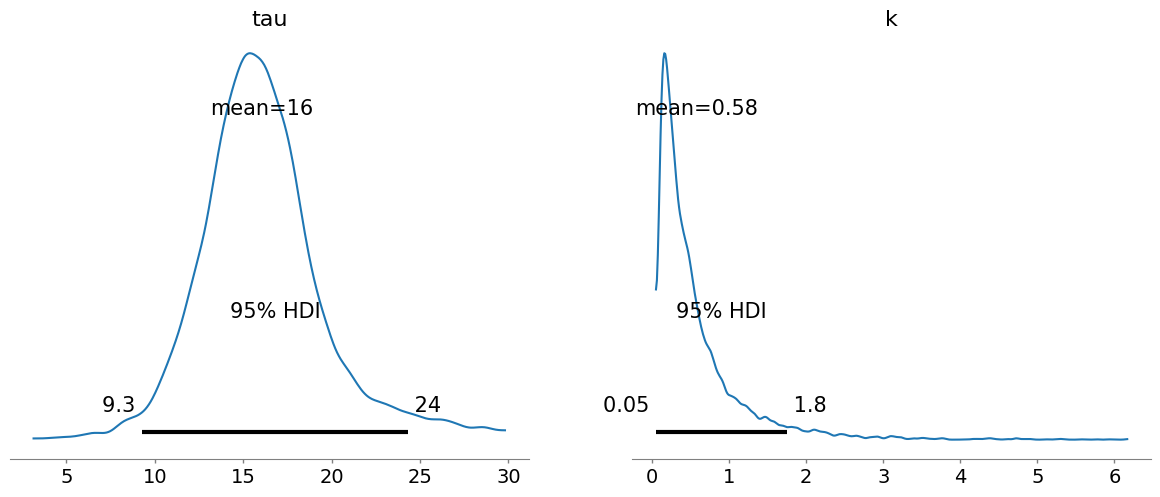

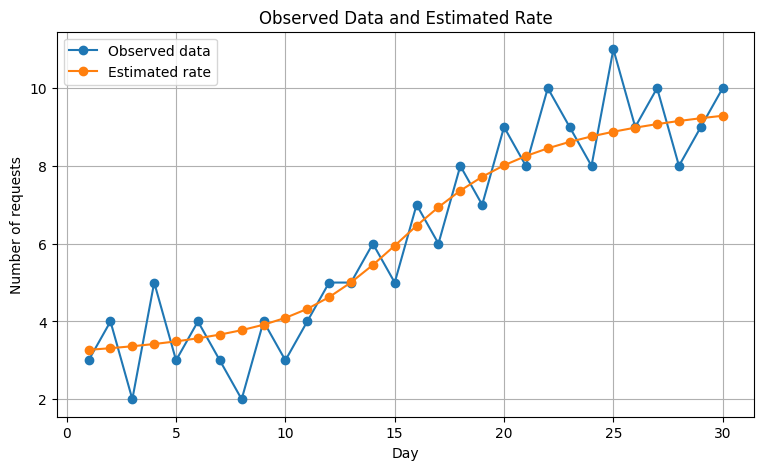

Output()

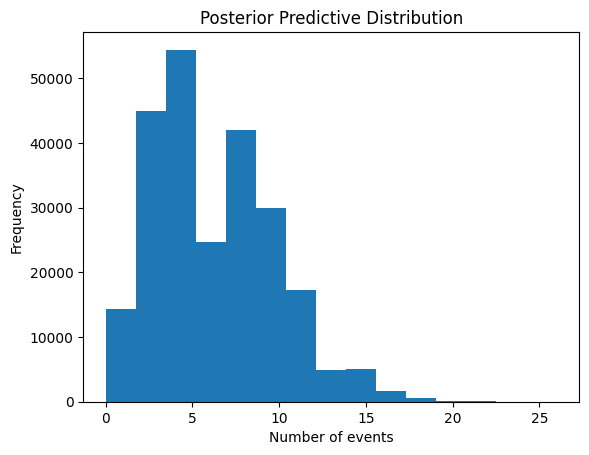

In [ ]:
#Exercise 3

import pymc as pm
import arviz as az
import numpy as np
import matplotlib.pyplot as plt

Y = np.array([
    3, 4, 2, 5, 3, 4, 3, 2, 4, 3,
    4, 5, 5, 6, 5, 7, 6, 8, 7, 9,
    8, 10, 9, 8, 11, 9, 10, 8, 9, 10
])

t = np.arange(1, 31)

#a

with pm.Model() as model:

    lambda1 = pm.Exponential("lambda1", lam=0.2)
    lambda2 = pm.Exponential("lambda2", lam=0.2)

    tau = pm.Uniform("tau", lower=1, upper=30)

    k = pm.Exponential("k", lam=1)

    lambda_t = lambda1 + ((lambda2 - lambda1) / (1 + pm.math.exp(-k * (t - tau))))

    lambda_t = pm.Deterministic("lambda_t", lambda_t)

    obs = pm.Poisson("obs", mu=lambda_t, observed=Y)

    idata = pm.sample(draws=2000, tune=2000, chains=4, target_accept=0.95, random_seed=42)
#b

az.plot_posterior(idata, var_names=["tau", "k"], hdi_prob=0.95)
plt.savefig("ex3_b_posterior_tau_k.png", dpi=300, bbox_inches="tight")
plt.show()

#c P(lambda2>lambda1|date)

lambda_t_samples = idata.posterior["lambda_t"].values

lambda_t_mean = lambda_t_samples.mean(axis=(0, 1))

plt.figure(figsize=(9, 5))

plt.plot(t, Y, "o-", label="Observed data")
plt.plot(t, lambda_t_mean, "o-", label="Estimated rate")

plt.xlabel("Day")
plt.ylabel("Number of requests")
plt.title("Observed Data and Estimated Rate")
plt.legend()
plt.grid(True)

plt.savefig("ex3_c_lambda_t.png", dpi=300, bbox_inches="tight")
plt.show()


# d - Posterior predictive

with model:
    ppc = pm.sample_posterior_predictive(idata, random_seed=42)

y_pred = ppc.posterior_predictive["obs"].values.flatten()

plt.hist(y_pred, bins=15)

plt.xlabel("Number of events")
plt.ylabel("Frequency")
plt.title("Posterior Predictive Distribution")
plt.savefig("ex3_d_predictive.png", dpi=300, bbox_inches="tight")
plt.show()

Exercise 3 (d)

The posterior predictive distribution generates possible values for the number of daily support requests over 30 days.

We compare the predicted values with the observed data to see how well the model describes the number of requests.

The model follows a gradual increase in the event rate, from the initial rate (lambda_1) to the final rate (lambda_2).

If the predicted values follow the general increasing trend in the observed data, we can say that the model captures the gradual transition.

Some differences between the observed and predicted values are normal because the daily number of requests is random and follows a Poisson distribution.